#### Autor: Leandro de Oliveira Nunes
#### Data ultima atualização: 14/11/2026
#### Exercício Visualização de Dados com Matplotlib e Seaborn

## Desafio: Análise a base de dados vendas_data_organized_1000.csv.
Veja que informações seriam importantes mostrar em um gráfico.

A entrega será texto explicativo da escolha do gráfico, pergunta norteadora e código aplicado.  
Mínimo  de 3 análises.

### Parte da base

ID_Transacao,Data_Venda,Cidade,Categoria,Quantidade,Preco_Unitario,Valor_Total  
TXN-10000,2024-01-01 00:00:00,Rio de Janeiro,InformÃ¡tica,2,90.39,180.78  
TXN-10001,2024-01-01 04:00:00,MacaÃ©,EletrodomÃ©sticos,6,1506.02,9036.119999999999  
TXN-10002,2024-01-01 08:00:00,PetrÃ³polis,MÃ³veis,5,1067.89,5339.450000000001  
TXN-10003,2024-01-01 12:00:00,NiterÃ³i,EletrodomÃ©sticos,9,1726.7,15540.300000000001  
TXN-10004,2024-01-01 16:00:00,Rio de Janeiro,EletrodomÃ©sticos,5,2041.34,10206.699999999999  
TXN-10005,2024-01-01 20:00:00,Rio de Janeiro,InformÃ¡tica,2,200.9,401.8  
TXN-10006,2024-01-02 00:00:00,Rio de Janeiro,EletrodomÃ©sticos,5,474.36,2371.8  
TXN-10007,2024-01-02 04:00:00,Volta Redonda,InformÃ¡tica,4,1977.32,7909.28  
TXN-10008,2024-01-02 08:00:00,PetrÃ³polis,EletrÃ´nicos,7,1233.93,8637.51  
TXN-10009,2024-01-02 12:00:00,PetrÃ³polis,EletrÃ´nicos,6,2565.65,15393.900000000001  
TXN-10010,2024-01-02 16:00:00,Rio de Janeiro,InformÃ¡tica,2,2300.41,4600.82  
TXN-10011,2024-01-02 20:00:00,MacaÃ©,EletrÃ´nicos,5,2967.34,14836.7  
TXN-10012,2024-01-03 00:00:00,Volta Redonda,MÃ³veis,7,2439.1,17073.7  
TXN-10013,2024-01-03 04:00:00,Rio de Janeiro,EletrodomÃ©sticos,7,1533.26,10732.82  


Gráfico escolhido é o de barras associado a faturamento por cidade, pois na base de dados temos categorias de produtos vendidos em um determinado período e dessa forma destaca melhor a diferença de faturamento já que tamanho ficará mais visível vendo a ordem entre as cidades.

2.

A pergunta que dará um norte seria qual cidade concentra o maior faturamento, e quanto ela representa do total?  
 Rio de Janeiro lidera com R$ 3.627.377,07, o equivalente a 41,3% do faturamento total. Niterói vem em seguida, com R$ 1.659.118,47 (18,9%). Macaé fica por último, com R$ 924.880,06.
 A Mediana foi de R$ 6.727,59 que representa com precisão a venda típica com a média alcançando R$ 8.791,73 acima dos valores da mediana porque a quantidade de produtos vndidos com menor valor superam os de maior.

3.

       Quantidade  Preco_Unitario   Valor_Total
count  1000.00000     1000.000000   1000.000000
mean      5.03600     1764.488690   8791.731850
std       2.54385      990.612723   7123.727855
min       1.00000       50.040000     56.870000
25%       3.00000      944.172500   2973.420000
50%       5.00000     1762.845000   6727.585000
75%       7.00000     2606.975000  13008.512500
max       9.00000     3492.480000  31029.840000


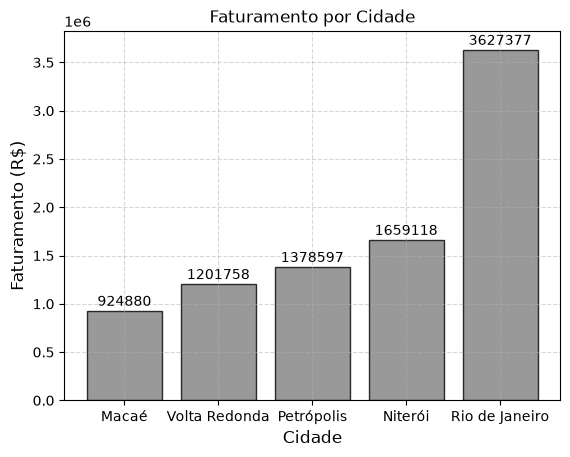

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Caminho dinâmico para a pasta 'Data' e o arquivo de vendas
caminho = Path("..") / "Data" / "vendas_data_organized_1000.csv"

df = pd.read_csv(caminho)

# Agrupa por cidade e soma o Valor_Total de cada uma (formato da aula de 28/10)
vendas_cidade = df.groupby("Cidade")["Valor_Total"].sum().sort_values()

# CORREÇÃO 1: Guardar o gráfico na variável 'barras' para o loop funcionar
barras = plt.bar(
    vendas_cidade.index,  # Eixo x: nomes das cidades
    vendas_cidade.values,  # Eixo y: faturamento de cada cidade
    color="gray",  # Adiciona cor personalizada às barras
    edgecolor="black",  # Adiciona cor à borda das barras
    alpha=0.8,  # Define a transparência das barras
)

# Adicionar valor exato no topo de cada barra (rótulo de dados)
for barra in barras:
    altura = barra.get_height()  # Obtém a altura da barra
    plt.text(  # Adiciona o texto com valor da altura da barra
        barra.get_x()  # posição horizontal da barra
        + barra.get_width() / 2.0,  # Posiciona o texto no centro da barra
        altura + 20000,  # Posição vertical do texto (escala de reais, não de unidades)
        f"{int(altura)}",  # Formata o valor da altura como inteiro
        ha="center",  # Alinha o texto horizontalmente ao centro
        va="bottom",  # Alinha o texto verticalmente em relação à barra
        fontsize=10,  # Define o tamanho da fonte do texto
    )

# Customizações do gráfico
plt.title("Faturamento por Cidade")  # Adiciona título ao gráfico
plt.xlabel("Cidade", fontsize=12)  # Eixo x
plt.ylabel("Faturamento (R$)", fontsize=12)  # Eixo y
plt.grid(True, linestyle="--", alpha=0.5)  # Linhas de grade mais suaves
plt.ylim(0, vendas_cidade.max() + 200000)  # Forçar o eixo Y a começar do zero

print(df.describe())
plt.show()  # Exibe o gráfico

1.

Foi escolhido um gráfico combinado de barras e as barras representam o faturamento bruto (R$) de cada categoria, enquanto a linha com eixo secundário exibe a participação percentual (%) na quantidade total de itens vendidos.  
Esse formato permite comparar se as categorias que mais faturam são também as que mais vendem em volume.

2.

Alguma categoria lidera as vendas de forma destacada, tanto em faturamento quanto em volume de unidades?  
Não há uma liderança isolada. Móveis lidera com 26,9% (R$ 2.364.377), e a menor é Eletrodomésticos com 23,6% (R$ 2.074.841). Uma diferença de apenas 3,3 pontos percentuais.  
Quantidade de Peças: A distribuição das quantidades é ainda mais equilibrada (todas entre 23,7% e 26,7%), com uma diferença máxima de 3,0 p.p. entre Móveis (1.344 un) e Informática (1.196 un).  
Insight Estratégico: Eletrodomésticos teve o menor faturamento em reais, mas vendeu mais unidades (1.213 un / 24,1%) que Informática (1.196 un / 23,7%), o que indica que os produtos de Informática possuem um valor unitário médio mais elevado.

3.

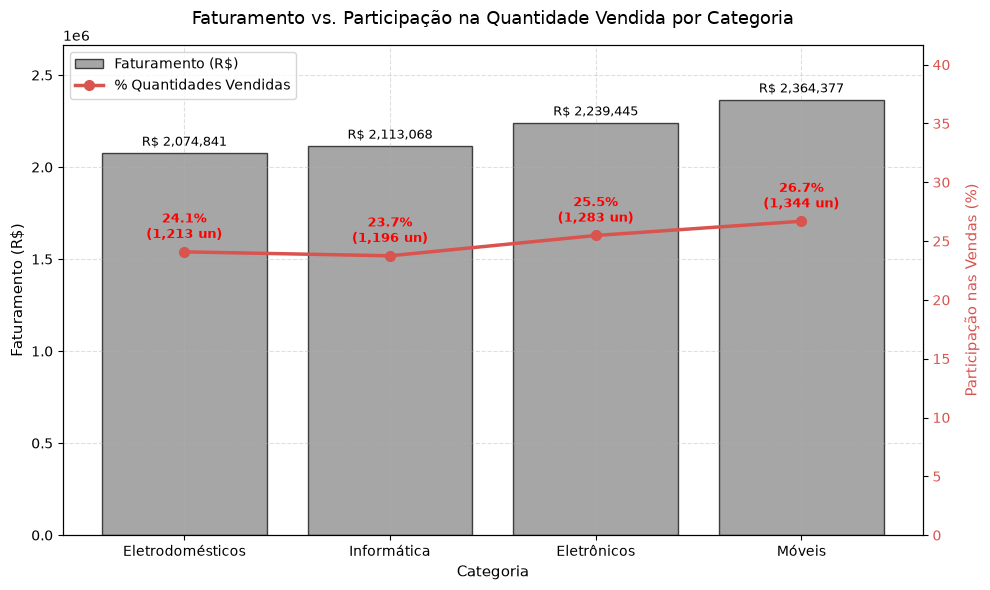

In [4]:
# ==============================================================================
# 1. IMPORTAÇÃO DE BIBLIOTECAS
# ==============================================================================
from pathlib import Path # Importa a classe Path para manipular caminhos de pastas de forma compatível com Windows/Linux/Mac
import matplotlib.pyplot as plt # Importa o módulo pyplot com o apelido 'plt' para criar e customizar gráficos
import pandas as pd # Importa a biblioteca pandas com o apelido 'pd' para carregar e manipular tabelas de dados


# ==============================================================================
# 2. CARREGAMENTO E PREPARAÇÃO DOS DADOS
# ==============================================================================
caminho = Path("..") / "Data" / "vendas_data_organized_1000.csv" # Define o caminho do arquivo: '..' volta um nível de pasta, entra em 'Data' e aponta para o CSV

df = pd.read_csv(caminho) # Lê o arquivo CSV e o transforma em uma estrutura de tabela (DataFrame)

faturamento_categoria = (
    df.groupby("Categoria") # Agrupa as linhas pela coluna 'Categoria'
    ["Valor_Total"].sum() # Seleciona a coluna de valores e soma o total faturado de cada grupo
    .sort_values() # Ordena os totais do menor faturamento para o maior
)

quantidade_categoria = (
    df.groupby("Categoria")["Quantidade"].sum() # Soma o número de unidades vendidas por categoria
    .loc[faturamento_categoria.index] # Reordena as quantidades para seguir a mesma ordem exata do faturamento
)

percentual_quantidade = (
    quantidade_categoria / quantidade_categoria.sum() # Calcula a soma de todas as unidades vendidas em todas as categorias
) * 100 # Divide a quantidade de cada categoria pelo total geral e multiplica por 100 para achar a porcentagem (%)


# ==============================================================================
# 3. CRIAÇÃO DA FIGURA E DO EIXO PRINCIPAL (BARRAS - FATURAMENTO)
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(10, 6)) # plt.subplots(): cria a janela do gráfico (fig) e o primeiro eixo de coordenadas (ax1) e # figsize=(10, 6): define o tamanho da imagem em 10 polegadas de largura por 6 de altura

barras = ax1.bar( # Desenha o gráfico de barras verticais no eixo primário (ax1)
    faturamento_categoria.index, # Passa os nomes das categorias para o eixo horizontal (X)
    faturamento_categoria.values, # Passa os valores numéricos de faturamento para o eixo vertical (Y)
    color="gray", # Define a cor interna das barras como cinza
    edgecolor="black", # Adiciona uma borda preta ao redor de cada barra
    alpha=0.7, # Define a transparência da barra em 70% de opacidade (para visual mais leve)
    label="Faturamento (R$)", # Nome que identifica as barras na legenda
)

for barra in barras: # Percorre cada uma das barras desenhadas para colocar o valor em texto acima delas
  altura = barra.get_height() # Método que extrai a altura da barra atual (que corresponde ao faturamento em R$)

  ax1.text( # escreve um texto no gráfico usando coordenadas (x, y)
      barra.get_x() + # Coordenada da borda esquerda da barra
      barra.get_width() / 2.0, # Metade da largura da barra (posiciona o X no centro exato)
      altura + 25000, # Posiciona o Y 25 mil unidades acima da barra para não sobrepor o desenho
      f"R$ {altura:,.0f}", # Formata o número com separador de milhar (,) e zero casas decimais (.0f)
      ha="center", # Alinhamento horizontal ao centro (horizontalalignment)
      va="bottom", # Alinhamento vertical pela base do texto (verticalalignment)
      fontsize=9, # Define o tamanho da fonte do texto
  )

ax1.set_title( # Define o título superior do gráfico; pad=15 cria 15 pontos de distância do topo
    "Faturamento vs. Participação na Quantidade Vendida por Categoria",
    fontsize=13, # Define o tamanho da fonte do texto
    pad=15,
)

# Definem os títulos dos eixos X e Y esquerdo
ax1.set_xlabel("Categoria", fontsize=11) # fontsize Define o tamanho da fonte do texto
ax1.set_ylabel("Faturamento (R$)", fontsize=11) # fontsize Define o tamanho da fonte do texto

ax1.grid(True, # Habilita a grade
         linestyle="--", # Deixa tracejada
         alpha=0.4) # Deixa suave

ax1.set_ylim(0, faturamento_categoria.max() + 300000) # Força o eixo Y esquerdo a iniciar em 0 e ir até o valor máximo + 300.000 (espaço para o texto)


# ==============================================================================
# 4. CRIAÇÃO DO EIXO SECUNDÁRIO E DA LINHA (PERCENTUAL DE QUANTIDADE)
# ==============================================================================
ax2 = ax1.twinx() # Função-chave que cria um segundo eixo vertical (ax2) à direita, compartilhando o mesmo eixo X

linha = ax2.plot( # Desenha o gráfico de linha no eixo secundário (ax2)
    percentual_quantidade.index, # Nomes das categorias (eixo X)
    percentual_quantidade.values, # Valores em porcentagem (eixo Y direito)
    color="#d9534f", # Cor vermelha/coral em código hexadecimal
    marker="o", # Coloca um ponto circular em cada categoria
    linewidth=2.5, # Espessura do traço da linha
    markersize=7, # Tamanho do círculo (marcador)
    label="% Quantidades Vendidas", # Identificação da linha para a legenda
)

ax2.set_ylabel( # Nomeia o eixo da direita
    "Participação nas Vendas (%)", color="#d9534f", fontsize=11, labelpad=10 # Afasta o texto dos números
)

ax2.tick_params(axis="y", labelcolor="#d9534f") # Estiliza a escala numérica da direita com a mesma cor vermelha da linha

ax2.set_ylim(0, percentual_quantidade.max() + 15) # Define a escala de porcentagem iniciando em 0% até o maior percentual + 15% (espaço para o texto)


# ==============================================================================
# 5. RÓTULOS DETALHADOS NOS PONTOS DA LINHA
# ==============================================================================
for cat, pct, qtd in zip( # Zip(): une 3 listas paralelas (nomes das categorias, % da quantidade e quantidade inteira em peças)
    percentual_quantidade.index,
    percentual_quantidade.values,
    quantidade_categoria.values,
):
  
  # (cat, pct): 
  # textcoords="offset points": 
  # xytext=(0, 10): 
  # ha="center": 
  # fontweight="bold": 
  ax2.annotate( # Adiciona texto posicionado de forma relativa a um ponto específico do gráfico
      f"{pct:.1f}%\n({qtd:,} un)", # Texto com porcentagem (1 casa decimal) + quebra de linha (\n) + unidades com vírgula
      (cat, pct), # Tupla de coordenadas exatas do ponto que queremos rotular
      textcoords="offset points", # Instrui que o deslocamento será em pontos geométricos relativos ao ponto
      xytext=(0, 10), # Move o texto 0 pontos horizontalmente e 10 pontos para cima do ponto da linha
      ha="center", # Centraliza o texto horizontalmente sobre o ponto
      color="red",  # Vermelho clássico de visualização
      fontweight="bold", # Deixa o texto em negrito para facilitar a leitura
      fontsize=9, # Define o tamanho da fonte do texto
  )


# ==============================================================================
# 6. UNIFICAÇÃO DA LEGENDA E EXIBIÇÃO
# ==============================================================================
linhas_1, labels_1 = ax1.get_legend_handles_labels() # Captura os desenhos gráficos (handles) e os textos (labels) de cada eixo
linhas_2, labels_2 = ax2.get_legend_handles_labels() # Captura os desenhos gráficos (handles) e os textos (labels) de cada eixo

ax1.legend( # Cria a legenda juntando as duas listas com '+' (barra cinza + linha vermelha)
  linhas_1 + linhas_2, labels_1 + labels_2, 
  loc="upper left") # Posiciona a caixa de legenda no canto superior esquerdo

# Reajusta automaticamente as margens da figura para não cortar nenhum texto ou rótulo
plt.tight_layout()

# Renderiza e exibe o gráfico finalizado na tela do Jupyter Notebook
plt.show()

1.

A escolha do gráfico foi escolhido de linhas com marcadores, para evidenciar tendências contínuas, sazonalidades e variações de desempenho ao longo do tempo (série temporal mensal).

2.

Como o faturamento da empresa se comportou ao longo do primeiro semestre de 2024?  

O faturamento manteve-se consistente, com média próxima a R$ 1,6 milhão por mês entre janeiro e maio.
Fevereiro registrou a menor receita entre os meses cheios (R$ 1,37M), impactado pela menor quantidade de dias no mês.
Alerta de análise: Junho aparenta uma queda acentuada (R$ 747 mil), porém a análise da base revela que os dados foram coletados apenas até o dia 15/06 (meio mês), e não por perda real de demanda.

3.

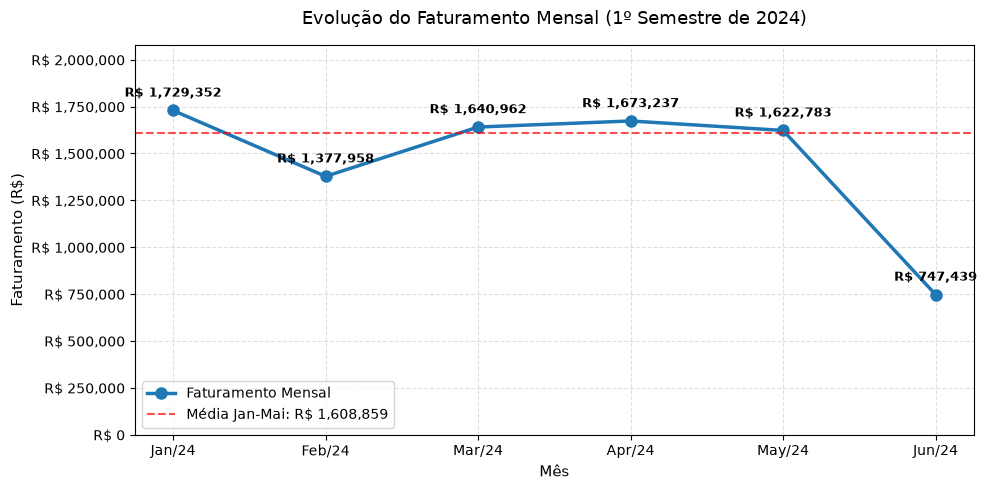

In [5]:
from pathlib import Path  # Importa a classe Path para manipulação de caminhos no sistema operacional
import matplotlib.pyplot as plt  # Importa a biblioteca de gráficos sob o apelido plt
import pandas as pd  # Importa a biblioteca de manipulação de dados sob o apelido pd

caminho = Path("..") / "Data" / "vendas_data_organized_1000.csv"  # Caminho dinâmico até o arquivo CSV
df = pd.read_csv(caminho)  # Carrega os dados do arquivo CSV em um DataFrame

df["Data_Venda"] = pd.to_datetime(df["Data_Venda"])  # Converte a coluna Data_Venda de texto para formato datetime real

faturamento_mensal = (  # Cria a série com a soma do faturamento mês a mês
    df.groupby(df["Data_Venda"].dt.to_period("M"))  # Agrupa as transações por ano e mês cronológico (ex: 2024-01)
    ["Valor_Total"].sum()  # Seleciona a coluna de receita e soma todos os valores de cada mês
)

meses_formatados = [  # Lista para armazenar os nomes dos meses formatados para o eixo X
    m.strftime("%b/%y").capitalize()  # Converte o período m em texto amigável com inicial maiúscula (ex: 'Jan/24')
    for m in faturamento_mensal.index  # Itera sobre cada período do índice da série faturamento_mensal
]
valores_mensais = faturamento_mensal.values  # Extrai os valores numéricos de faturamento de cada mês em um array

fig, ax = plt.subplots(  # Cria a figura (janela) e o eixo (área do gráfico)
    figsize=(10, 5)  # Define o tamanho da figura em 10 polegadas de largura por 5 de altura
)

linha = ax.plot(  # Desenha a linha temporal no gráfico
    meses_formatados,  # Dados do eixo horizontal X: lista de meses formatados
    valores_mensais,  # Dados do eixo vertical Y: valores de faturamento em R$
    marker="o",  # Adiciona marcadores circulares em cada ponto de dado mensal
    color="#1f77b4",  # Define a cor azul padrão para o traçado da linha
    linewidth=2.5,  # Define a espessura do traço da linha em 2.5 pontos
    markersize=8,  # Define o diâmetro dos círculos marcadores em 8 pontos
    label="Faturamento Mensal",  # Nome da série que será exibido na legenda do gráfico
)

media_mensal = valores_mensais[:-1].mean()  # Calcula a média aritmética de faturamento dos meses cheios (Jan a Mai)
ax.axhline(  # Desenha uma linha horizontal de apoio no gráfico
    media_mensal,  # Posição Y da linha correspondente ao valor da média calculada
    color="#FF0000",  # Define a cor vermelha para destacar a linha da média
    linestyle="--",  # Define o traço como tracejado para diferenciar da linha principal
    alpha=0.7,  # Define a transparência da linha em 70% de visibilidade
    label=f"Média Jan-Mai: R$ {media_mensal:,.0f}",  # Rótulo explicativo da linha de média na legenda
)

for mes, valor in zip(meses_formatados, valores_mensais):  # Percorre em paralelo os nomes dos meses e os valores de faturamento
    ax.annotate(  # Adiciona rótulo de texto explicativo vinculado ao ponto da linha
        f"R$ {valor:,.0f}",  # Formata o número como valor monetário com separador de milhar
        (mes, valor),  # Coordenada exata (x, y) do ponto do gráfico a ser rotulado
        textcoords="offset points",  # Define que o deslocamento do texto será medido em pontos
        xytext=(0, 10),  # Desloca o texto 0 pontos na horizontal e 10 pontos para cima do marcador
        ha="center",  # Centraliza o texto horizontalmente sobre o marcador
        fontsize=9,  # Define o tamanho da fonte do texto como 9 pontos
        fontweight="bold",  # Aplica peso negrito ao texto para facilitar a leitura
    )

ax.set_title(  # Define o título principal da visualização
    "Evolução do Faturamento Mensal (1º Semestre de 2024)",  # Texto do título
    fontsize=13,  # Tamanho da fonte do título
    pad=15,  # Espaçamento de 15 pontos entre o título e o topo do gráfico
)
ax.set_xlabel("Mês", fontsize=11)  # Define o texto e o tamanho da fonte do rótulo do eixo X
ax.set_ylabel("Faturamento (R$)", fontsize=11)  # Define o texto e o tamanho da fonte do rótulo do eixo Y
ax.grid(True, linestyle="--", alpha=0.4)  # Ativa a grade de fundo tracejada com transparência suave

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"R$ {y:,.0f}"))  # Formata o eixo Y em Reais (R$) sem notação 1e6

ax.set_ylim(0, valores_mensais.max() + 350000)  # Define os limites inferior (0) e superior do eixo Y com margem para o texto
ax.legend(loc="lower left")  # Exibe a caixa de legenda posicionada no canto inferior esquerdo

plt.tight_layout()  # Ajusta automaticamente as margens da figura para não cortar rótulos nem títulos
plt.show()  # Renderiza e exibe o gráfico finalizado na tela

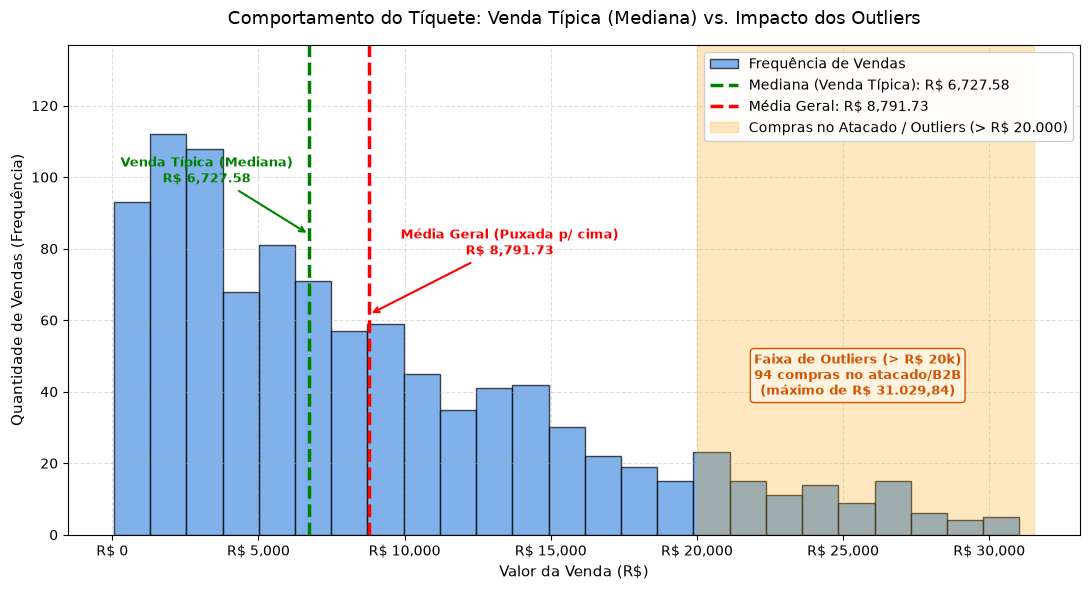

In [6]:
from pathlib import Path  # Importa a classe Path para manipulação de caminhos no sistema
import matplotlib.pyplot as plt  # Importa o módulo de gráficos com o apelido plt
import pandas as pd  # Importa a biblioteca de manipulação de dados com o apelido pd

caminho = (
    Path("..") / "Data" / "vendas_data_organized_1000.csv"
)  # Caminho dinâmico até o arquivo de vendas
df = pd.read_csv(caminho)  # Carrega a base de dados em um DataFrame

media = (
    df["Valor_Total"].mean()  # Calcula a média aritmética de todas as vendas
)
mediana = (
    df["Valor_Total"].median()  # Calcula o valor central (mediana) das vendas
)

fig, ax = plt.subplots(  # Cria a figura e o eixo do gráfico
    figsize=(11,6,)  # Define a proporção com 11 polegadas de largura por 6 de altura
)

n, bins, barras = ax.hist(  # Desenha o histograma de distribuição das vendas
    df["Valor_Total"],  # Coluna de valores totais de cada transação
    bins=25,  # Divide os dados em 25 faixas de valores (barras)
    color="#4a90e2",  # Define a cor azul suave para as barras
    edgecolor="black",  # Adiciona borda preta em volta de cada barra
    alpha=0.7,  # Define a transparência em 70% para suavizar o visual
    label="Frequência de Vendas",  # Identificação da série na legenda
)

ax.axvline(  # Desenha a linha vertical da Mediana
    mediana,  # Posição X da linha referente ao valor exato da mediana
    color="green",  # Cor verde destacando a venda típica
    linestyle="--",  # Estilo tracejado para diferenciar da grade
    linewidth=2.5,  # Espessura destacada da linha em 2.5 pontos
    label=(
        f"Mediana (Venda Típica): R$ {mediana:,.2f}"  # Texto explicativo para a"
                                                      # " legenda
    ),
)

ax.axvline(  # Desenha a linha vertical da Média
    media,  # Posição X da linha referente ao valor da média
    color="red",  # Cor vermelha indicando o desvio causado por outliers
    linestyle="--",  # Estilo tracejado para diferenciar da grade
    linewidth=2.5,  # Espessura destacada da linha em 2.5 pontos
    label=(
        f"Média Geral: R$ {media:,.2f}"  # Texto explicativo para a legenda
    ),
)

ax.axvspan(  # Cria uma área sombreada na faixa de valores extremos
    20000,  # Início da área sombreada em R$ 20.000,00
    df["Valor_Total"].max()
    + 500,  # Fim da área no valor máximo da base (R$ 31.029,84)
    color="orange",  # Cor laranja para alertar a faixa de compras corporativas
    alpha=0.25,  # Transparência suave para não esconder as barras
    label=(
        "Compras no Atacado / Outliers (> R$ 20.000)"  # Rótulo da área na"
                                                       # " legenda
    ),
)

ax.annotate(  # Adiciona anotação com seta apontando para a Mediana
    f"Venda Típica (Mediana)\nR$ {mediana:,.2f}",  # Texto exibindo a mediana
    xy=(
        mediana,
        n.max() * 0.75,
    ),  # Coordenada exata da ponta da seta na linha da mediana
    xytext=(
        mediana - 3500,
        n.max() * 0.88,
    ),  # Coordenada onde o texto ficará posicionado
    arrowprops=dict(
        arrowstyle="->", color="green", lw=1.5
    ),  # Configuração da seta verde
    fontsize=9.5,  # Tamanho da fonte do texto
    fontweight="bold",  # Negrito para facilitar a leitura
    color="green",  # Cor do texto combinando com a linha
    ha="center",  # Alinhamento horizontal centralizado
)

ax.annotate(  # Adiciona anotação com seta apontando para a Média
    f"Média Geral (Puxada p/ cima)\nR$ {media:,.2f}",  # Texto exibindo a média
    xy=(media, n.max() * 0.55),  # Coordenada da ponta da seta na linha da média
    xytext=(
        media + 4800,
        n.max() * 0.70,
    ),  # Coordenada onde o texto ficará posicionado
    arrowprops=dict(
        arrowstyle="->", color="red", lw=1.5
    ),  # Configuração da seta vermelha
    fontsize=9.5,  # Tamanho da fonte do texto
    fontweight="bold",  # Negrito para facilitar a leitura
    color="red",  # Cor do texto combinando com a linha
    ha="center",  # Alinhamento horizontal centralizado
)

ax.text(  # Insere caixa de texto explicativa na área de Outliers
    25500,  # Posição horizontal no centro da faixa de R$ 20k a R$ 31k
    n.max() * 0.35,  # Posição vertical na altura das barras dessa região
    "Faixa de Outliers (> R$ 20k)\n94 compras no atacado/B2B\n(máximo de R$"
    " 31.029,84)",  # Texto explicativo
    fontsize=9,  # Tamanho da fonte do texto
    fontweight="bold",  # Negrito para destacar a informação
    color="#d35400",  # Cor laranja escura
    ha="center",  # Centraliza o texto horizontalmente
    bbox=dict(
        boxstyle="round,pad=0.3", fc="#fff3e0", ec="#d35400", lw=1
    ),  # Desenha caixinha de destaque ao redor do texto
)

ax.set_title(  # Define o título principal do gráfico
    "Comportamento do Tíquete: Venda Típica (Mediana) vs. Impacto dos Outliers",  # Título
    fontsize=13,  # Tamanho da fonte do título
    pad=15,  # Espaçamento de 15 pontos do topo
)
ax.set_xlabel(
    "Valor da Venda (R$)", fontsize=11
)  # Define o rótulo do eixo horizontal
ax.set_ylabel(
    "Quantidade de Vendas (Frequência)", fontsize=11
)  # Define o rótulo do eixo vertical
ax.grid(
    True, linestyle="--", alpha=0.4
)  # Habilita a grade tracejada com transparência suave

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"R$ {x:,.0f}")
)  # Formata o eixo X em formato de moeda (R$)

ax.set_ylim(
    0, n.max() + 25
)  # Define limite vertical com margem superior para as anotações
ax.legend(
    loc="upper right", framealpha=0.95
)  # Exibe a legenda completa no canto superior direito

plt.tight_layout()  # Ajusta as margens para não cortar textos nem eixos
plt.show()  # Renderiza o gráfico finalizado na tela

Com base nas quatro análises visuais realizadas sobre a base de dados do 1º Semestre de 2024, destacam-se os seguintes diagnósticos para a tomada de decisão:

### 1. Resumo
* **Concentração Regional:** O **Rio de Janeiro** é a região top, gerando **41,3%** de todo o faturamento da empresa (R$ 3,62 milhões de R$ 8,79 milhões). Cidades como **Macaé** (R$ 924 mil) e **Volta Redonda** (R$ 1,2 milhão) ainda representam fatias menores e têm potencial de crescimento.
* **Equilíbrio de Portfólio:** As quatro categorias de produtos apresentam fatias muito equilibradas (entre **23,6%** e **26,9%**). **Móveis** lidera tanto em faturamento quanto em volume de unidades vendidas (26,7%), indicando alta aceitação do catálogo.
* **Comportamento do Tíquete:** A venda típica do dia a dia gira em torno de **R$ 6.727,59** (mediana). A média mais elevada (**R$ 8.791,73**) decorre de compras corporativas e compras no atacado que ultrapassam **R$ 20.000,00** (outliers). Explicando melhor, a montanha de vendas à esquerda e a imensa maioria das transações do dia a dia concentrando abaixo de R$ 10.000, onde a Mediana (R$ 6.727,59) representa com precisão a venda típica. Quanto ao desvio da Média seria a Média (R$ 8.791,73) ficando deslocada mais de R$ 2.000 à direita da mediana, comprovando a assimetria positiva (right-skewed). Ainda tem a faixa sombreada de Outliers (> R$ 20.000) que destaca visualmente em laranja as 94 vendas corporativas/atacado que chegam até R$ 31.029,84, justificando exatamente o motivo pelo qual a média foi puxada para cima.
* **Consistência Mensal:** O negócio mantém receita recorrente estável em torno de **R$ 1,6 milhão por mês** entre janeiro e maio. A queda aparente em junho é explicada pela coleta parcial de dados (até o dia 15/06).